1.เตรียมข้อมูล

In [34]:
import kagglehub
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, r2_score, classification_report

# --- 1.1 Download & Load Data ---
path = kagglehub.dataset_download("ganiyuolalekan/uefa-champions-league-202122")
files = [f for f in os.listdir(path) if f.endswith('.csv')]

try:
    df = pd.read_csv(os.path.join(path, files[0]), encoding='latin1')
except:
    df = pd.read_csv(os.path.join(path, files[0]), encoding='cp1252')

# ล้างชื่อคอลัมน์ให้เป็นระเบียบ
df.columns = df.columns.str.strip().str.lower()

# --- 1.2 Data Cleaning ---
# เลือกเฉพาะคอลัมน์ตัวเลขเพื่อใช้ในโมเดล และจัดการค่าว่างด้วยการเติม 0 หรือ Mean
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
df[num_cols] = df[num_cols].fillna(df[num_cols].median())

print(f"Dataset Loaded: {df.shape[0]} rows, {df.shape[1]} columns")

Dataset Loaded: 32 rows, 66 columns


2. การวิเคราะห์ข้อมูลเชิงสำรวจ

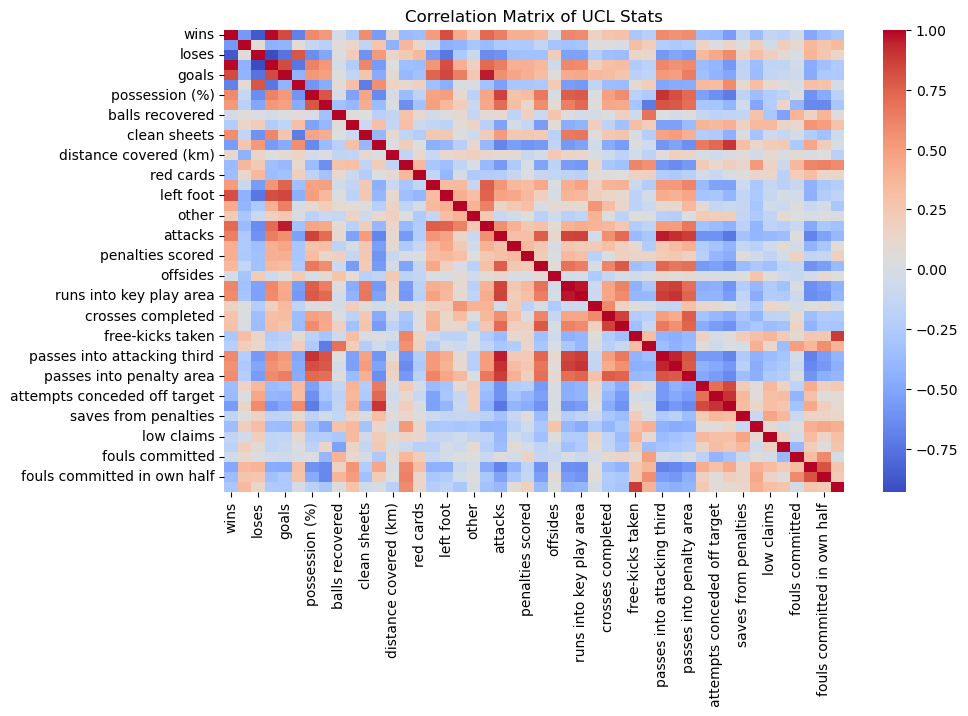

In [35]:
# ดูความสัมพันธ์ของสถิติสำคัญ (เช่น Wins vs Goals)
plt.figure(figsize=(10, 6))
sns.heatmap(df[num_cols].corr(), annot=False, cmap='coolwarm')
plt.title("Correlation Matrix of UCL Stats")
plt.show()

3. การสร้างแบบจำลองและการฝึกฝน

3.1 Regression Model (การวิเคราะห์แนวโน้ม)

In [36]:
# ใช้ Wins (ชัยชนะ) ทำนาย Points (คะแนนรวม)
col_x, col_y = 'wins', 'points'
X_reg = df[[col_x]]
y_reg = df[col_y]

reg_model = LinearRegression()
reg_model.fit(X_reg, y_reg)
y_pred = reg_model.predict(X_reg)

print(f"Regression Result: R-squared = {r2_score(y_reg, y_pred):.4f}")

Regression Result: R-squared = 0.9771


3.2Classification Model (การจำแนกกลุ่ม)

In [37]:
# สร้าง Target: 1 คือคะแนนสูงกว่าค่ากลาง, 0 คือทั่วไป
target_val = df['points'].median()
df['performance_level'] = (df['points'] > target_val).astype(int)

# เตรียมข้อมูลสำหรับ Classification
X = df[num_cols].drop(['points'], axis=1) # ตัดตัวแปรที่ใช้สร้าง target ออก
y = df['performance_level']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# มาตรฐานข้อมูล (Scaling) เป็นขั้นตอนสำคัญมากสำหรับ SVM และ KNN
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# เทรน 3 โมเดลเพื่อเปรียบเทียบ
models = {
    "Logistic Regression": LogisticRegression(),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Support Vector Machine": SVC(kernel='linear', probability=True)
}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)

4.การวัดผล

In [38]:
print("--- Model Performance ---")
for name, model in models.items():
    y_pred_class = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred_class)
    print(f"{name} Accuracy: {acc:.2%}")
    # แสดง Report เชิงลึก
    # print(classification_report(y_test, y_pred_class))

--- Model Performance ---
Logistic Regression Accuracy: 57.14%
K-Nearest Neighbors Accuracy: 71.43%
Support Vector Machine Accuracy: 57.14%


5. การนำเสนอและการทำนายผล

In [39]:
def predict_performance(stats_input):
    """
    stats_input: list ของตัวเลขสถิติตามจำนวน Feature
    """
    scaled_input = scaler.transform([stats_input])
    prediction = models["Support Vector Machine"].predict(scaled_input)
    
    status = "🌟 High Performance" if prediction[0] == 1 else "📊 Normal Performance"
    return status

# ทดสอบทำนายด้วยข้อมูลแถวแรกของ Test Set
sample_stats = X_test.iloc[0].values
print(f"ผลการทำนายสำหรับทีมตัวอย่าง: {predict_performance(sample_stats)}")

ผลการทำนายสำหรับทีมตัวอย่าง: 📊 Normal Performance


C:\Users\USER\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
